# DS02 · Geçmiş özellik karşılaştırması

Aynı 256/256 pencere modeline 18 `mean_to_date` özelliği eklemek yeni bir
motorun RUL tahminini nasıl değiştiriyor? Colab çalışma zamanında hücreleri
sırayla çalıştırın. DS02 dev verisi kullanılır. Eksik pencere metadata’sı
Drive’daki HDF5 dosyasından oluşturulur.

In [1]:
import hashlib
import json
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display
from xgboost import XGBRegressor

drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive/ncmapss")
h5_path = drive_root / "N-CMAPSS_DS02-006.h5"
metadata_path = drive_root / "ds02_w256_s256" / "window_metadata.csv"
output_dir = drive_root / "deneyler" / "xgboost_v02_gecmis_karsilastirmasi"

def read_names(dataset):
    return [
        value.decode("utf-8").rstrip("\x00") if isinstance(value, bytes) else str(value)
        for value in np.asarray(dataset[()]).reshape(-1)
    ]


WINDOW_SIZE = 256
STRIDE = 256
FLIGHT_KEYS = ["unit", "cycle"]
META_COLUMNS = ["window_id", *FLIGHT_KEYS, "rul", "start_row", "end_row"]

if not h5_path.is_file():
    raise FileNotFoundError(h5_path)


def read_dev_flights(path):
    with h5py.File(path, "r") as h5:
        id_names = read_names(h5["A_var"])
        if id_names[:2] != FLIGHT_KEYS:
            raise ValueError("DS02 A_dev sütun sırası beklenen unit, cycle ile başlamıyor.")
        identifiers = h5["A_dev"][:, :2].astype(np.int32)
        starts = np.r_[0, np.flatnonzero(np.any(identifiers[1:] != identifiers[:-1], axis=1)) + 1]
        ends = np.r_[starts[1:], len(identifiers)]
        targets = h5["Y_dev"][starts, 0]

    flights = pd.DataFrame(identifiers[starts], columns=FLIGHT_KEYS)
    return flights.assign(start_row=starts, end_row=ends, rul=targets.astype(float))


def build_window_metadata(flights):
    records = []
    for flight in flights.itertuples(index=False):
        for start in range(flight.start_row, flight.end_row - WINDOW_SIZE + 1, STRIDE):
            records.append((len(records), flight.unit, flight.cycle, flight.rul, start, start + WINDOW_SIZE))
    return pd.DataFrame(records, columns=META_COLUMNS)


def validate_generated_metadata(windows, flights):
    if len(flights) != 446 or flights.duplicated(FLIGHT_KEYS).any():
        raise ValueError("HDF5 içinde 446 benzersiz dev uçuşu bekleniyor.")
    if len(windows) != 20_339 or not windows["window_id"].is_unique:
        raise ValueError("20.339 benzersiz pencere bekleniyor.")

    groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    for flight in flights.itertuples(index=False):
        group = groups.pop((flight.unit, flight.cycle))
        count = (flight.end_row - flight.start_row) // WINDOW_SIZE
        starts = flight.start_row + np.arange(count) * STRIDE
        ends = group["end_row"].to_numpy()
        np.testing.assert_array_equal(group["start_row"], starts)
        np.testing.assert_array_equal(ends, starts + WINDOW_SIZE)
        if np.any(ends > flight.end_row):
            raise ValueError(f"Pencere uçuş sınırını aşıyor: {flight.unit}, {flight.cycle}")
    if groups:
        raise ValueError("Metadata içinde HDF5 ile eşleşmeyen uçuş var.")


def load_window_metadata(path, flights):
    if path.is_file():
        print(f"Hazır metadata kullanılıyor: {path}")
        return pd.read_csv(path, dtype={column: "int64" for column in META_COLUMNS if column != "rul"})

    windows = build_window_metadata(flights)
    validate_generated_metadata(windows, flights)
    path.parent.mkdir(parents=True, exist_ok=True)
    windows.to_csv(path, index=False, lineterminator="\r\n")
    print(f"{len(flights)} uçuş ve {len(windows):,} benzersiz pencere doğrulandı. Metadata kaydedildi: {path}")
    return windows


dev_flights = read_dev_flights(h5_path)
metadata = load_window_metadata(metadata_path, dev_flights)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Hazır metadata kullanılıyor: /content/drive/MyDrive/ncmapss/ds02_w256_s256/window_metadata.csv


## Ortak pencereler

V02-36, 18 kanalın pencere ortalamalarını ve popülasyon standart sapmalarını
kullanır. V02-54 aynı tabloya 18 birikimli uçuş ortalaması ekler. Bu
ortalamalara mevcut uçuş ve pencereye sığmayan ham satırlar da dahildir.

In [2]:
assert list(metadata.columns) == META_COLUMNS
assert len(metadata) == 20_339 and metadata["window_id"].is_unique
metadata = metadata.sort_values("window_id", ignore_index=True)


def extract_features(path, windows, flights):
    window_groups = {key: group for key, group in windows.groupby(FLIGHT_KEYS, sort=False)}
    v02_blocks = []
    flight_mean_rows = []
    with h5py.File(path, "r") as h5:
        groups = [(h5[f"{key}_dev"], [f"{key}_{name}" for name in read_names(h5[f"{key}_var"])])
                  for key in ("W", "X_s")]
        feature_columns = [
            f"{name}_{stat}"
            for _, names in groups
            for stat in ("mean", "std")
            for name in names
        ]
        mean_columns = [f"{name}_mean" for _, names in groups for name in names]
        assert [len(names) for _, names in groups] == [4, 14]
        assert len(set(feature_columns)) == 36

        for unit, cycle, start, end, rul in flights.itertuples(index=False, name=None):
            flight_windows = window_groups.pop((unit, cycle)).sort_values("start_row")
            expected_starts = np.arange(start, end - WINDOW_SIZE + 1, WINDOW_SIZE)
            np.testing.assert_array_equal(flight_windows["start_row"], expected_starts)
            np.testing.assert_array_equal(flight_windows["end_row"], expected_starts + WINDOW_SIZE)
            np.testing.assert_allclose(flight_windows["rul"], rul, rtol=0, atol=0)

            flight_means = []
            window_features = []
            for dataset, names in groups:
                raw = dataset[start:end]
                window_rows = raw[:len(expected_starts) * WINDOW_SIZE].reshape(
                    len(expected_starts), WINDOW_SIZE, len(names)
                )
                flight_means.extend(np.mean(raw, axis=0, dtype=np.float64))
                window_features.extend([
                    np.mean(window_rows, axis=1, dtype=np.float64),
                    np.std(window_rows, axis=1, dtype=np.float64, ddof=0),
                ])

            flight_mean_rows.append((unit, cycle, rul, *flight_means))
            stats = pd.DataFrame(np.hstack(window_features), index=flight_windows.index, columns=feature_columns)
            v02_blocks.append(flight_windows.join(stats))

    assert not window_groups
    v02 = pd.concat(v02_blocks).sort_index().rename(columns={"rul": "RUL"})
    flight_means = pd.DataFrame(flight_mean_rows, columns=[*FLIGHT_KEYS, "RUL", *mean_columns])
    flight_means = flight_means.sort_values(FLIGHT_KEYS, ignore_index=True)
    assert not flight_means.duplicated(FLIGHT_KEYS).any()
    history = (
        flight_means.groupby("unit", sort=False)[mean_columns]
        .expanding().mean().droplevel("unit").add_suffix("_to_date")
    )
    return flight_means.join(history), v02, feature_columns



flight_means, windows, features_36 = extract_features(h5_path, metadata, dev_flights)
history_columns = [col for col in flight_means if col.endswith("_mean_to_date")]
assert len(history_columns) == 18
features_54 = [*features_36, *history_columns]
history = flight_means.set_index(FLIGHT_KEYS)[history_columns]
windows_54 = windows.merge(
    history.reset_index(), on=FLIGHT_KEYS, how="left", sort=False, validate="many_to_one"
)
expected_history = history.loc[pd.MultiIndex.from_frame(windows_54[FLIGHT_KEYS])]
assert windows_54[history_columns].notna().all().all()
np.testing.assert_array_equal(windows_54[history_columns], expected_history)
shared = ["window_id", *FLIGHT_KEYS, "RUL", *features_36]
pd.testing.assert_frame_equal(windows[shared], windows_54[shared], check_exact=True)

actual_flights = flight_means[[*FLIGHT_KEYS, "RUL"]].sort_values(FLIGHT_KEYS, ignore_index=True)
units = sorted(windows["unit"].unique())
assert len(units) == 6 and len(actual_flights) == 446
assert len(windows[FLIGHT_KEYS].drop_duplicates()) == 446
assert windows[features_36].shape == (20_339, 36)
assert windows_54[features_54].shape == (20_339, 54)
print("20.339 pencerenin kimlikleri, hedefleri ve ortak 36 girdisi birebir eşleşti.")

20.339 pencerenin kimlikleri, hedefleri ve ortak 36 girdisi birebir eşleşti.


## Motor bazlı eğitim

Her dış katta bir motor ayrılır. Kalan beş motor iç doğrulamada sırayla ayrılır.
Her uçuş eğitimde eşit toplam ağırlık alır. İki model de 3.000 ağaç sınırı
ve 50 turluk erken durdurmayla, pencere tahminlerinin uçuş medyanından
hesaplanan uçuş RMSE’sini izler. Dış model, kendi beş iç katının en iyi ağaç
sayılarının medyanıyla eğitilir.

In [3]:
model_params = dict(
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
)

def flight_weights(frame):
    counts = frame.groupby(FLIGHT_KEYS)["RUL"].transform("size")
    weights = 1.0 / counts.to_numpy()
    return weights / weights.mean()


MAX_TREES = 3000
EARLY_STOPPING_ROUNDS = 50


def make_flight_rmse(validation):
    flight_codes = validation.groupby(FLIGHT_KEYS, sort=False).ngroup().to_numpy()
    actual = validation.groupby(FLIGHT_KEYS, sort=False)["RUL"].first().to_numpy()

    def flight_rmse(_window_rul, predictions):
        medians = pd.Series(predictions).groupby(flight_codes, sort=False).median().to_numpy()
        return float(np.sqrt(np.mean(np.square(medians - actual))))

    return flight_rmse


def select_rounds(training, columns, version, outer_unit):
    folds = []
    for_fold_curves = []
    for unit in sorted(training["unit"].unique()):
        inner_train = training.loc[training["unit"] != unit]
        inner_valid = training.loc[training["unit"] == unit]
        params = model_params.copy()
        params["eval_metric"] = make_flight_rmse(inner_valid)
        params["disable_default_eval_metric"] = True

        model = XGBRegressor(**params, n_estimators=MAX_TREES, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
        model.fit(
            inner_train[columns], inner_train["RUL"],
            sample_weight=flight_weights(inner_train),
            eval_set=[(inner_valid[columns], inner_valid["RUL"])],
            verbose=False,
        )
        curve = model.evals_result()["validation_0"]["flight_rmse"]
        folds.append({
            "Model": version, "Dış motor": outer_unit, "İç motor": unit,
            "Seçilen ağaç": model.best_iteration + 1, "Denenen ağaç": len(curve),
        })
        for_fold_curves.append(pd.DataFrame({
            "Model": version, "Dış motor": outer_unit, "İç motor": unit,
            "Ağaç": np.arange(1, len(curve) + 1), "RMSE": curve,
        }))
    return pd.DataFrame(folds), pd.concat(for_fold_curves, ignore_index=True)


def predict_outer_folds(frame, columns, version):
    predictions = []
    diagnostics = []
    curves = []
    for unit in units:
        training = frame.loc[frame["unit"] != unit]
        held_out = frame.loc[frame["unit"] == unit]
        folds, fold_curves = select_rounds(training, columns, version, unit)
        rounds = int(folds["Seçilen ağaç"].median())
        diagnostics.append(folds)
        curves.append(fold_curves)
        model = XGBRegressor(**model_params, n_estimators=rounds)
        model.fit(training[columns], training["RUL"], sample_weight=flight_weights(training))

        ids = ["window_id"] if "window_id" in frame.columns else []
        result = held_out[[*ids, *FLIGHT_KEYS, "RUL"]].copy()
        result[version] = model.predict(held_out[columns])
        predictions.append(result)
        print(f"{version} | Motor {unit} | {rounds} ağaç")
    return (
        pd.concat(predictions).sort_index(),
        pd.concat(diagnostics, ignore_index=True),
        pd.concat(curves, ignore_index=True),
    )



def fit_flight_predictions(frame, columns, version):
    oof, _, _ = predict_outer_folds(frame, columns, version)
    pd.testing.assert_index_equal(pd.Index(oof["window_id"]), pd.Index(frame["window_id"]))
    return oof.groupby(FLIGHT_KEYS, as_index=False).agg(
        RUL=("RUL", "first"), **{version: (version, "median")}
    )

## Kayıtlı V02-54 tahminleri

Yeniden kullanım için kayıt, deney ayarlarını ve eğitim girdisinin parmak
izini doğrulayan bir JSON dosyasıyla eşleşmelidir. Eski notebook’un yalnızca
tahmin CSV’si varsa ağaç sınırı ve seçim ölçütü doğrulanamaz. Bu karşılaştırma
kendi doğrulanabilir V02-54 kaydını yazar ve sonraki çalıştırmalarda kullanır.

In [4]:
def sha256(data):
    return hashlib.sha256(data).hexdigest()


def validate_flight_predictions(frame, version):
    frame = frame[[*FLIGHT_KEYS, "RUL", version]].sort_values(FLIGHT_KEYS, ignore_index=True)
    if len(frame) != 446 or frame.duplicated(FLIGHT_KEYS).any():
        raise ValueError("Tahmin kaydı 446 benzersiz uçuş içermeli.")
    pd.testing.assert_frame_equal(frame[actual_flights.columns], actual_flights,
                                  check_exact=True, check_dtype=False)
    if not np.isfinite(frame[version].to_numpy(dtype=float)).all():
        raise ValueError("Tahminler sonlu olmalı.")
    return frame


input_columns = ["window_id", *FLIGHT_KEYS, "RUL", *features_54]
input_hash = sha256(windows_54[input_columns].to_numpy(dtype="<f8").tobytes())
protocol = {
    "model": "V02-54",
    "split": "DS02-006_dev",
    "window_size": WINDOW_SIZE,
    "stride": STRIDE,
    "input_columns": input_columns,
    "input_sha256": input_hash,
    "outer_units": [int(unit) for unit in units],
    "inner_split": "leave_one_engine_out_within_outer_training",
    "model_params": model_params,
    "max_trees": MAX_TREES,
    "early_stopping_rounds": EARLY_STOPPING_ROUNDS,
    "selection": "flight_rmse_of_window_medians_then_median_best_rounds",
    "weights": "inverse_windows_per_flight_normalized_to_mean_one",
    "prediction": "flight_median_of_outer_held_out_windows",
}


def load_v02_54(candidates):
    for csv_path, prediction_column in candidates:
        manifest_path = csv_path.with_suffix(".json")
        if not csv_path.is_file() or not manifest_path.is_file():
            continue
        try:
            manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
            if manifest.get("protocol") != protocol or manifest.get("csv_sha256") != sha256(csv_path.read_bytes()):
                continue
            frame = pd.read_csv(csv_path, float_precision="round_trip").rename(columns={prediction_column: "V02-54"})
            frame = validate_flight_predictions(frame, "V02-54")
        except (OSError, ValueError, KeyError, TypeError, AttributeError, AssertionError) as error:
            print(f"V02-54 kaydı kullanılamadı: {error}")
            continue
        print(f"V02-54 tahminleri yeniden kullanılıyor: {csv_path}")
        return frame
    return None


cache_csv = output_dir / "v02_54_dis_kat_tahminleri.csv"
legacy_csv = drive_root / "deneyler" / "xgboost_v02_pencere256_54ozellik" / "ucus_tahminleri.csv"
flights_54 = load_v02_54([(cache_csv, "V02-54"), (legacy_csv, "V02")])
if flights_54 is None:
    flights_54 = validate_flight_predictions(
        fit_flight_predictions(windows_54, features_54, "V02-54"), "V02-54"
    )
    output_dir.mkdir(parents=True, exist_ok=True)
    flights_54.to_csv(cache_csv, index=False, encoding="utf-8-sig")
    cache_csv.with_suffix(".json").write_text(
        json.dumps({"protocol": protocol, "csv_sha256": sha256(cache_csv.read_bytes())},
                   ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

flights_36 = validate_flight_predictions(
    fit_flight_predictions(windows, features_36, "V02-36"), "V02-36"
)

V02-54 | Motor 2 | 72 ağaç
V02-54 | Motor 5 | 92 ağaç
V02-54 | Motor 10 | 111 ağaç
V02-54 | Motor 16 | 160 ağaç
V02-54 | Motor 18 | 69 ağaç
V02-54 | Motor 20 | 136 ağaç
V02-36 | Motor 2 | 2310 ağaç
V02-36 | Motor 5 | 2771 ağaç
V02-36 | Motor 10 | 2341 ağaç
V02-36 | Motor 16 | 2440 ağaç
V02-36 | Motor 18 | 2297 ağaç
V02-36 | Motor 20 | 2996 ağaç


## Uçuş bazlı sonuçlar

Fark `54 − 36` olarak hesaplanır. Negatif fark, geçmiş özellikleri
eklendiğinde hatanın azaldığı anlamına gelir.

In [5]:
flight_predictions = flights_36.merge(
    flights_54.drop(columns="RUL"), on=FLIGHT_KEYS, validate="one_to_one"
).sort_values(FLIGHT_KEYS, ignore_index=True)
assert len(flight_predictions) == 446

metric_rows = []
for label, flights in [*flight_predictions.groupby("unit"), ("Tümü", flight_predictions)]:
    row = {"Motor": label, "Uçuş sayısı": len(flights)}
    errors = flights[["V02-36", "V02-54"]].sub(flights["RUL"], axis=0)
    for name, scores in [("MAE", errors.abs().mean()), ("RMSE", np.sqrt(errors.pow(2).mean()))]:
        row[f"{name} V02-36"] = scores["V02-36"]
        row[f"{name} V02-54"] = scores["V02-54"]
        row[f"{name} farkı (54 − 36)"] = scores["V02-54"] - scores["V02-36"]
    metric_rows.append(row)
metrics = pd.DataFrame(metric_rows)
display(metrics.round(3))

,Motor,Uçuş sayısı,MAE V02-36,MAE V02-54,MAE farkı (54 − 36),RMSE V02-36,RMSE V02-54,RMSE farkı (54 − 36)
0,2,75,8.660,6.024,-2.636,9.908,8.019,-1.889
1,5,89,10.013,10.836,0.823,14.799,14.924,0.125
2,10,82,8.374,8.497,0.123,11.157,11.457,0.301
3,16,63,8.006,7.719,-0.287,9.185,10.268,1.083
4,18,71,6.485,11.772,5.287,7.823,14.371,6.548
5,20,66,8.238,17.648,9.410,9.655,22.171,12.515
6,Tümü,446,8.376,10.314,1.937,10.888,14.139,3.251


## Motor 20 · Son 10 uçuş

In [6]:
motor_20 = (
    flight_predictions.loc[flight_predictions["unit"] == 20, ["cycle", "RUL", "V02-36", "V02-54"]]
    .tail(10).rename(columns={"cycle": "Uçuş sırası", "RUL": "Gerçek RUL"})
)
assert len(motor_20) == 10
display(motor_20.round(3))

,Uçuş sırası,Gerçek RUL,V02-36,V02-54
436,57,9.0,13.921,12.193000
437,58,8.0,12.886,10.521000
438,59,7.0,9.308,11.785000
439,60,6.0,9.569,9.387000
440,61,5.0,8.178,8.409000
441,62,4.0,6.020,8.043000
442,63,3.0,5.932,10.502000
443,64,2.0,-2.462,46.922001
444,65,1.0,-0.173,53.754002
445,66,0.0,-4.030,46.540001


## Motor grafikleri

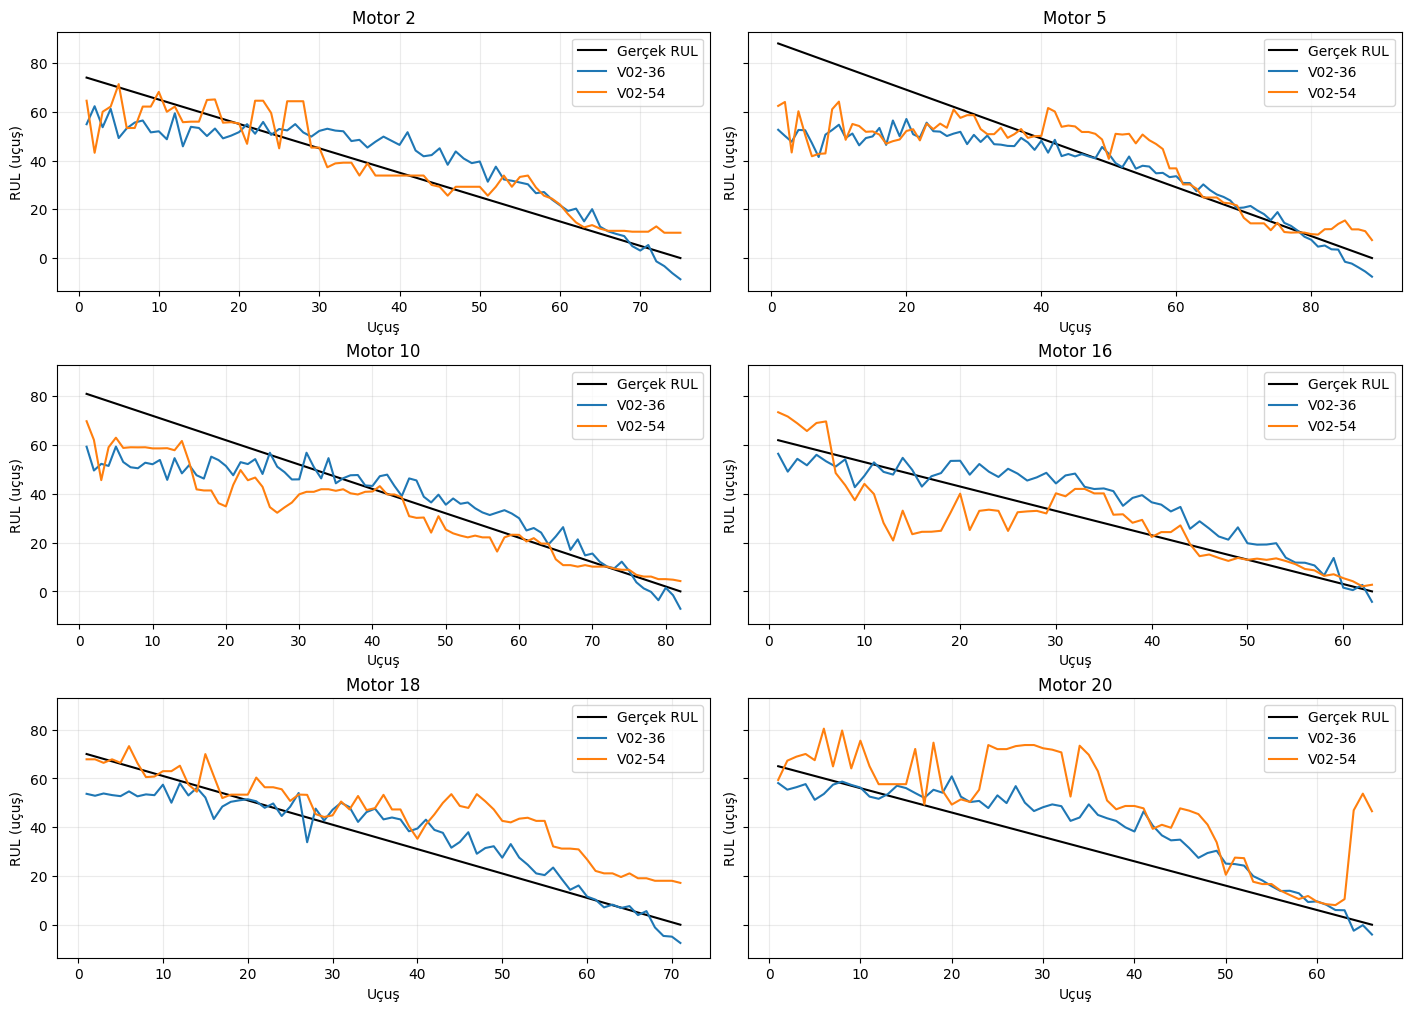

In [7]:
prediction_fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharey=True, layout="constrained")
for ax, (unit, flights) in zip(axes.flat, flight_predictions.groupby("unit")):
    ax.plot(flights["cycle"], flights["RUL"], label="Gerçek RUL", color="black")
    ax.plot(flights["cycle"], flights["V02-36"], label="V02-36")
    ax.plot(flights["cycle"], flights["V02-54"], label="V02-54")
    ax.set(title=f"Motor {unit}", xlabel="Uçuş", ylabel="RUL (uçuş)")
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

## Drive kaydı

In [8]:
output_dir.mkdir(parents=True, exist_ok=True)
flight_predictions.to_csv(output_dir / "ucus_tahminleri.csv", index=False, encoding="utf-8-sig")
metrics.to_csv(output_dir / "karsilastirma_metrikleri.csv", index=False, encoding="utf-8-sig")
motor_20.to_csv(output_dir / "motor_20_son_10_ucus.csv", index=False, encoding="utf-8-sig")
prediction_fig.savefig(output_dir / "motor_tahminleri.png", dpi=150)
print(output_dir)

/content/drive/MyDrive/ncmapss/deneyler/xgboost_v02_gecmis_karsilastirmasi
